# Ford Price Prediction

**Question:** Can we estimate the asking price (GBP) of a used Ford from its model, year, transmission, mileage, fuel type, tax, fuel economy, and engine size?

**Target:** `price` (GBP). 

## 01 | Imports and reproducibility

In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
DATA_PATH = Path("ford.csv")
CLEAN_PATH = Path("ford_cleaned.csv")
assert DATA_PATH.exists(), f"Place ford.csv beside this notebook (looked in {Path.cwd()})"
print("Working directory:", Path.cwd())

Working directory: C:\Users\hp\Documents\Codex\2026-11-05\create-a-new-folder-which-has\outputs\ford_used_car_price_prediction


## 02 | Load and inspect the source

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Raw shape:", raw.shape)
display(raw.head())
raw.info()

Raw shape: (17966, 9)
     model  year  price transmission  mileage fuelType  tax   mpg  engineSize
0   Fiesta  2017  12000    Automatic    15944   Petrol  150 57.70        1.00
1    Focus  2018  14000       Manual     9083   Petrol  150 57.70        1.00
2    Focus  2017  13000       Manual    12456   Petrol  150 57.70        1.00
3   Fiesta  2019  17500       Manual    10460   Petrol  145 40.30        1.50
4   Fiesta  2019  16500    Automatic     1482   Petrol  145 48.70        1.00
<class 'pandas.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  str    
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  str    
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  str    
 6   tax           17966 non-null  int64  
 7   mpg           17966 n

In [3]:
display(raw.describe(include="all").T)
missing = pd.DataFrame({"count": raw.isna().sum(), "percent": raw.isna().mean().mul(100)})
display(missing)
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Columns:", raw.columns.tolist())

                 count unique      top   freq      mean       std      min      25%       50%       75%        max
model            17966     24   Fiesta   6557       NaN       NaN      NaN      NaN       NaN       NaN        NaN
year         17,966.00    NaN      NaN    NaN  2,016.87      2.05 1,996.00 2,016.00  2,017.00  2,018.00   2,060.00
price        17,966.00    NaN      NaN    NaN 12,279.53  4,741.34   495.00 8,999.00 11,291.00 15,299.00  54,995.00
transmission     17966      3   Manual  15518       NaN       NaN      NaN      NaN       NaN       NaN        NaN
mileage      17,966.00    NaN      NaN    NaN 23,362.61 19,472.05     1.00 9,987.00 18,242.50 31,060.00 177,644.00
fuelType         17966      5   Petrol  12179       NaN       NaN      NaN      NaN       NaN       NaN        NaN
tax          17,966.00    NaN      NaN    NaN    113.33     62.01     0.00    30.00    145.00    145.00     580.00
mpg          17,966.00    NaN      NaN    NaN     57.91     10.13    20.80    52

## 03 | Data cleaning and decisions

The source has exact duplicate listings and whitespace around model labels. Exact duplicates are removed because they are identical across all nine fields and would otherwise over-weight those records. Category whitespace is trimmed. The single future-year record (2060) is inspected and excluded: the rest of this source spans 1996–2020, so 2060 is inconsistent with this historical listing snapshot, and there is no independent evidence to justify changing it to a guessed year. Zero engine size is retained as unknown (missing) rather than treated as a real engine displacement; the numeric pipeline will impute its median within each training fold. No other valid-looking extreme is dropped merely for being an outlier. No missing values were present in the raw file.

In [4]:
df = raw.copy()
rows_before = len(df)
# Normalize categorical labels without changing their meaning.
for col in ["model", "transmission", "fuelType"]:
    df[col] = df[col].astype("string").str.strip()

# Report suspicious and invalid values before applying explicit rules.
checks = {
    "price <= 0": df["price"] <= 0,
    "mileage < 0": df["mileage"] < 0,
    "tax < 0": df["tax"] < 0,
    "year outside observed snapshot (1996-2020)": (df["year"] < 1996) | (df["year"] > 2020),
    "engineSize == 0": df["engineSize"] == 0,
}
for label, mask in checks.items():
    print(f"{label}: {int(mask.sum())}")
    if label.startswith("year outside") and mask.any():
        display(df.loc[mask])

duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
# Future year cannot be corrected from this file alone; exclude and document it.
future_year_mask = df["year"] > 2020
future_years_excluded = int(future_year_mask.sum())
df = df.loc[~future_year_mask].copy()
# A zero displacement is not plausible; retain the listing and mark feature unknown.
zero_engine_count = int((df["engineSize"] == 0).sum())
df.loc[df["engineSize"] == 0, "engineSize"] = np.nan
assert (df["price"] > 0).all()
assert (df["mileage"] >= 0).all() and (df["tax"] >= 0).all()
df.to_csv(CLEAN_PATH, index=False)
print(f"Rows: {rows_before:,} -> {len(df):,}; exact duplicates removed: {duplicates_removed}; unsupported future-year rows excluded: {future_years_excluded}; zero engine sizes marked missing: {zero_engine_count}")
print("Exported cleaned data to:", CLEAN_PATH.resolve())
print("Remaining missing values:")
display(df.isna().sum().to_frame("count"))

price <= 0: 0
mileage < 0: 0
tax < 0: 0
year outside observed snapshot (1996-2020): 1
        model  year  price transmission  mileage fuelType  tax   mpg  engineSize
17726  Fiesta  2060   6495    Automatic    54807   Petrol  205 42.80        1.40
engineSize == 0: 51
Rows: 17,966 -> 17,811; exact duplicates removed: 154; unsupported future-year rows excluded: 1; zero engine sizes marked missing: 51
Exported cleaned data to: C:\Users\hp\Documents\Codex\2026-11-05\create-a-new-folder-which-has\outputs\ford_used_car_price_prediction\ford_cleaned.csv
Remaining missing values:
              count
model             0
year              0
price             0
transmission      0
mileage           0
fuelType          0
tax               0
mpg               0
engineSize       51


In [5]:
# Re-read the exported cleaned file; all downstream EDA and modeling use this file.
df = pd.read_csv(CLEAN_PATH)
print("Cleaned shape:", df.shape)
print("Remaining exact duplicates:", int(df.duplicated().sum()))
display(df.head())

Cleaned shape: (17811, 9)
Remaining exact duplicates: 0
    model  year  price transmission  mileage fuelType  tax   mpg  engineSize
0  Fiesta  2017  12000    Automatic    15944   Petrol  150 57.70        1.00
1   Focus  2018  14000       Manual     9083   Petrol  150 57.70        1.00
2   Focus  2017  13000       Manual    12456   Petrol  150 57.70        1.00
3  Fiesta  2019  17500       Manual    10460   Petrol  145 40.30        1.50
4  Fiesta  2019  16500    Automatic     1482   Petrol  145 48.70        1.00


## 04 | Exploratory analysis

The plots below answer questions about the target distribution, numeric relationships, category-level price variation, and numeric feature redundancy. Interpret patterns as associations in these listings, not causal effects.

       price (GBP)
count    17,811.00
mean     12,269.88
std       4,736.22
min         495.00
10%       7,200.00
25%       8,999.00
50%      11,289.00
75%      15,295.00
90%      18,390.00
99%      26,353.90
max      54,995.00


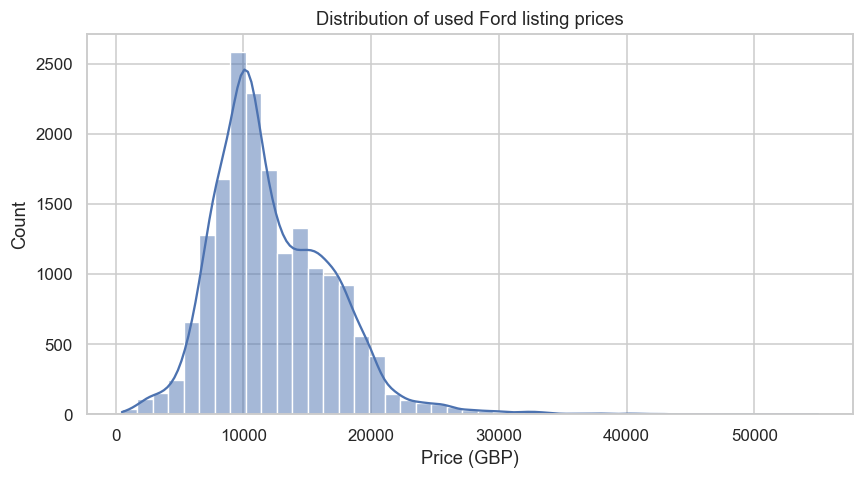

In [6]:
display(df["price"].describe(percentiles=[.10, .25, .50, .75, .90, .99]).to_frame("price (GBP)"))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df, x="price", bins=45, kde=True, ax=ax)
ax.set(title="Distribution of used Ford listing prices", xlabel="Price (GBP)")
fig.tight_layout()
plt.show()

In [7]:
categorical_cols = ["model", "transmission", "fuelType"]
for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} categories")
    display(df[col].value_counts(dropna=False).head(15).to_frame("listings"))

model: 23 categories
                listings
model                   
Fiesta              6508
Focus               4556
Kuga                2208
EcoSport            1127
C-MAX                542
Ka+                  523
Mondeo               512
B-MAX                350
S-MAX                294
Grand C-MAX          247
Galaxy               227
Edge                 205
KA                   197
Puma                  79
Tourneo Custom        69
transmission: 3 categories
              listings
transmission          
Manual           15383
Automatic         1353
Semi-Auto         1075
fuelType: 5 categories
          listings
fuelType          
Petrol       12080
Diesel        5706
Hybrid          22
Electric         2
Other            1


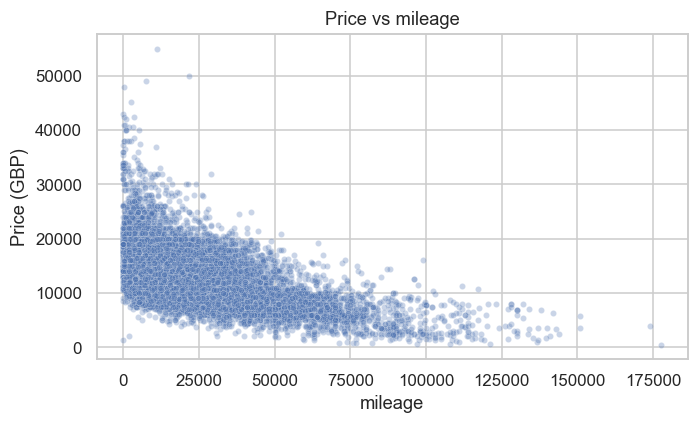

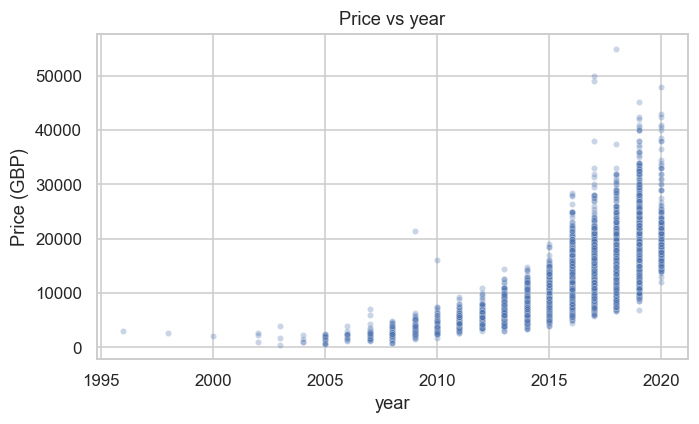

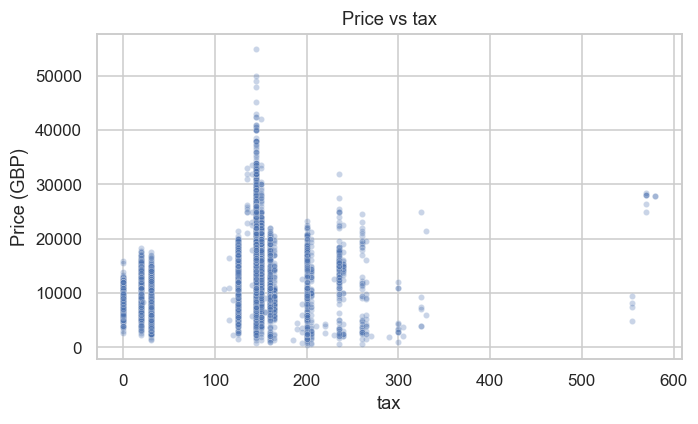

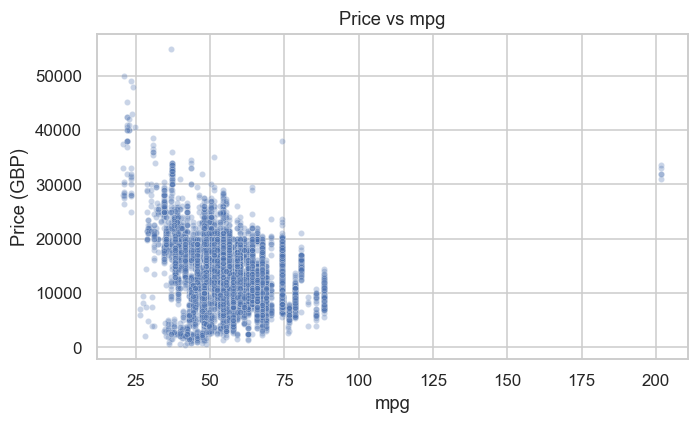

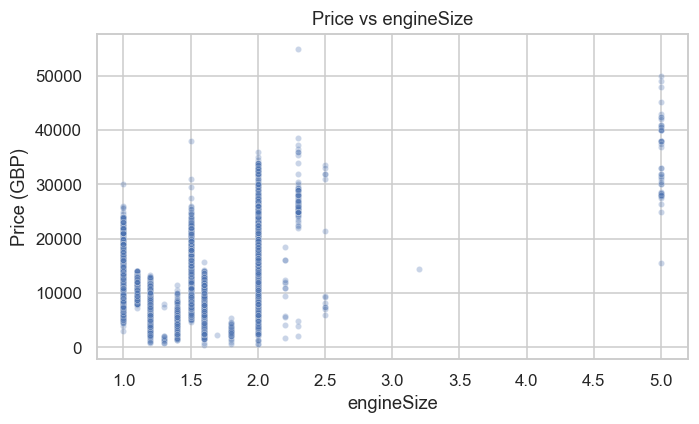

In [8]:
for col in ["mileage", "year", "tax", "mpg", "engineSize"]:
    fig, ax = plt.subplots(figsize=(6.5, 4))
    sns.scatterplot(data=df, x=col, y="price", alpha=.30, s=16, ax=ax)
    ax.set(title=f"Price vs {col}", ylabel="Price (GBP)")
    fig.tight_layout()
    plt.show()

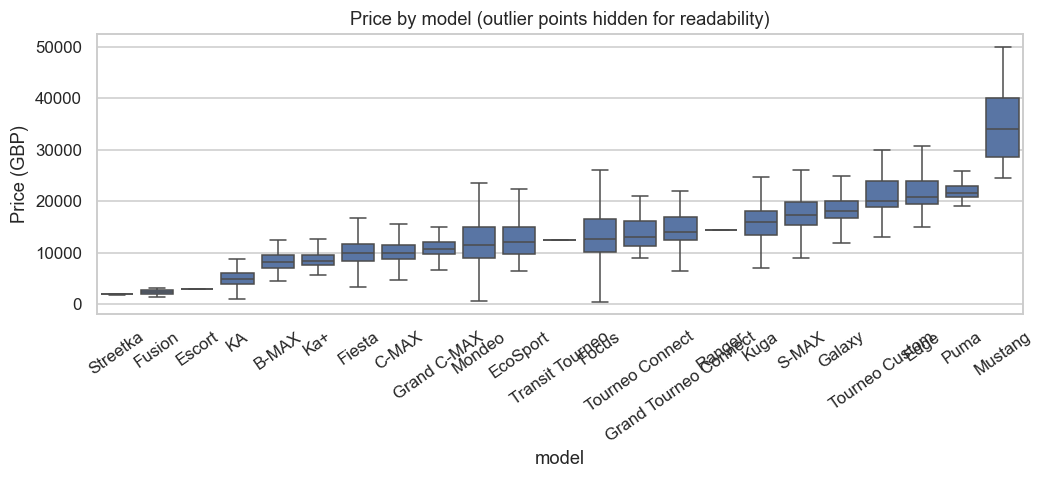

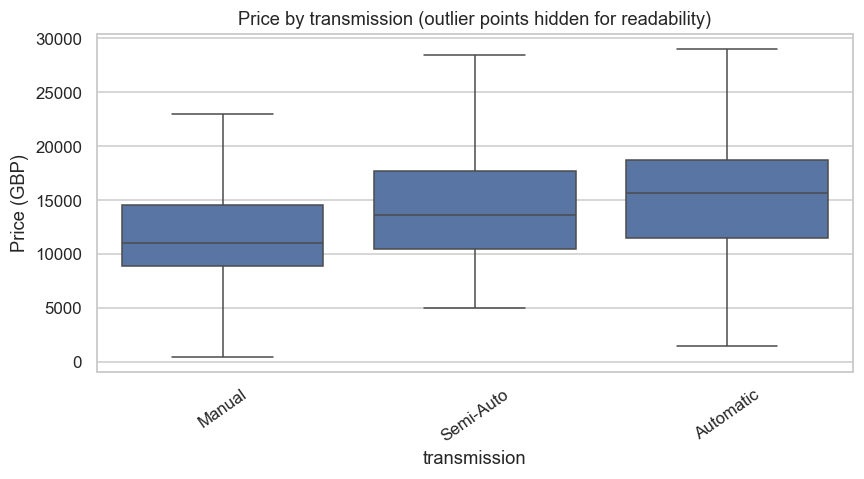

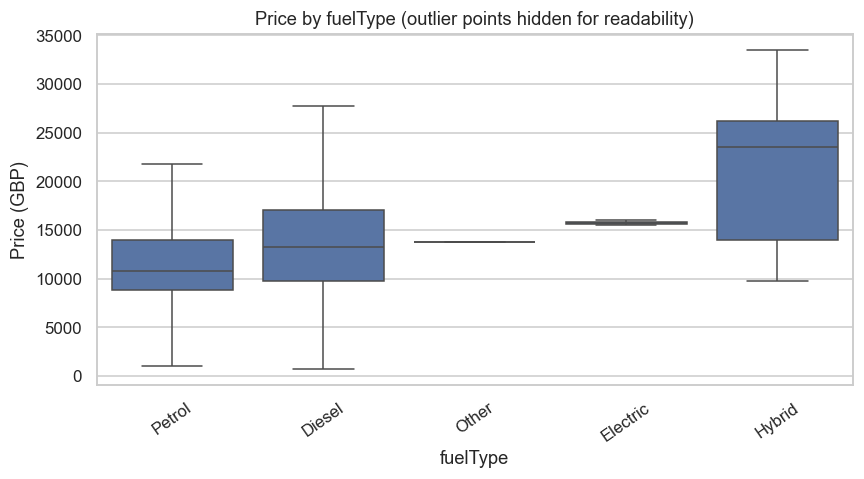

In [9]:
for col in ["model", "transmission", "fuelType"]:
    order = df.groupby(col, observed=True)["price"].median().sort_values().index
    fig, ax = plt.subplots(figsize=(max(8, len(order) * .42), 4.5))
    sns.boxplot(data=df, x=col, y="price", order=order, showfliers=False, ax=ax)
    ax.tick_params(axis="x", rotation=35)
    ax.set(title=f"Price by {col} (outlier points hidden for readability)", ylabel="Price (GBP)")
    fig.tight_layout()
    plt.show()

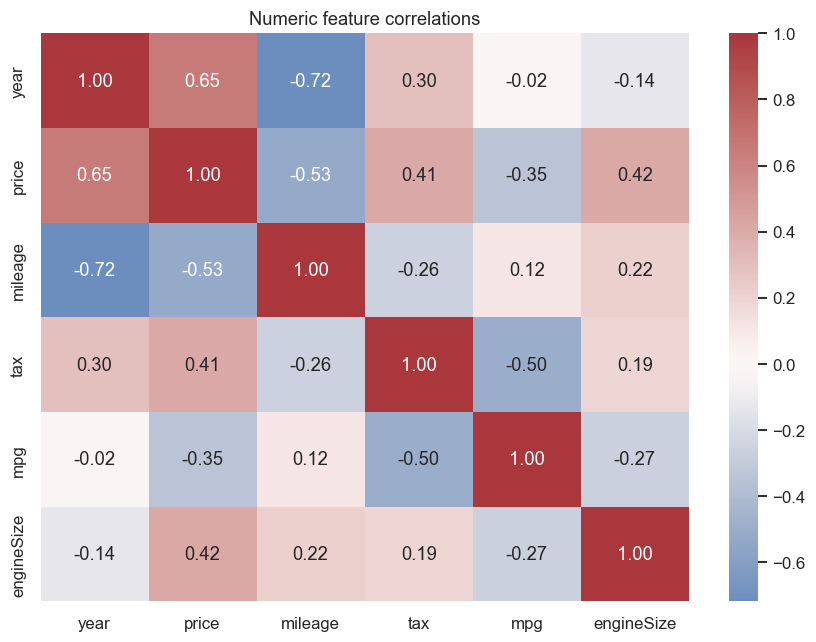

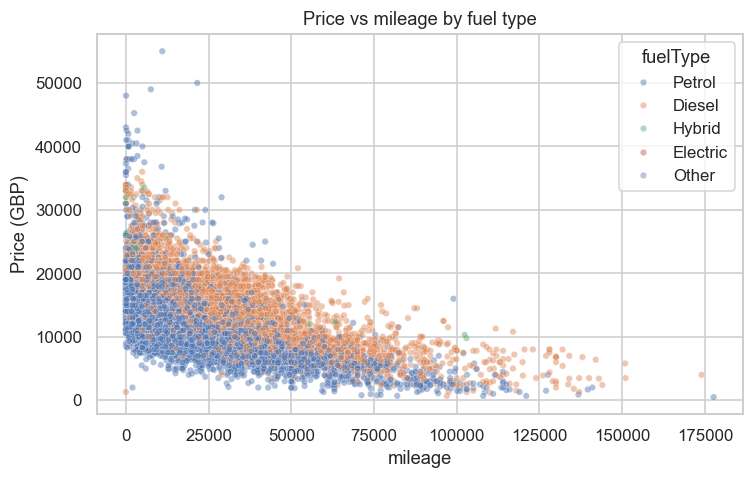

In [10]:
numeric_corr = df.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric_corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Numeric feature correlations")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=df, x="mileage", y="price", hue="fuelType", alpha=.45, s=18, ax=ax)
ax.set(title="Price vs mileage by fuel type", ylabel="Price (GBP)")
fig.tight_layout()
plt.show()

### Reading the EDA

Use the displayed summaries and plots to describe the observed price range and skew, how price varies with mileage/year, category differences, and whether the category groups are uneven. The numerical summaries above are the evidence; avoid causal claims. The historical source has a 1996–2020 year range after the documented future-year exclusion. Distribution tails and overlapping groups make residual diagnostics especially relevant.

## 05 | Feature choices, split, and preprocessing

Use the cleaned `year` directly; do not derive a stale `car_age` from the current calendar year. Keep all measured input features, including year. Split first, then fit imputation, scaling, and category encoding only inside each pipeline fold. The 20% holdout is reserved for final evaluation. No target-derived feature or target-based row filtering is used.

In [11]:
TARGET = "price"
X = df.drop(columns=TARGET).copy()
y = df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

Train rows: 14,248; test rows: 3,563
Numeric features: ['year', 'mileage', 'tax', 'mpg', 'engineSize']
Categorical features: ['model', 'transmission', 'fuelType']


## 06 | Baseline and candidate regressors

All models receive the same training split and preprocessing. Five-fold shuffled CV is run on training data only. RMSE is the selection metric; MAE and R² provide complementary context. The holdout is not inspected during model selection.\n\nTo keep this project runnable on a typical laptop, each tree ensemble uses 100 trees; all model families are compared under the same five-fold protocol.

To keep this project runnable on a typical laptop, each tree ensemble uses 100 trees; all model families are compared under the same five-fold protocol.

In [12]:
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=1.0),
    "Random forest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra trees": ExtraTreesRegressor(
        n_estimators=100, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Hist gradient boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
rows, fitted = [], {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    fitted[name] = pipe
    rows.append({
        "Model": name,
        "CV MAE (GBP)": -scores["test_mae"].mean(),
        "CV RMSE (GBP)": -scores["test_rmse"].mean(),
        "CV R2": scores["test_r2"].mean(),
        "RMSE fold SD (GBP)": scores["test_rmse"].std(),
    })
comparison = pd.DataFrame(rows).sort_values("CV RMSE (GBP)").reset_index(drop=True)
display(comparison)
best_name = comparison.loc[0, "Model"]
best_model = fitted[best_name]
print("Selected using training-only CV RMSE:", best_name)

                    Model  CV MAE (GBP)  CV RMSE (GBP)  CV R2  RMSE fold SD (GBP)
0             Extra trees        822.68       1,218.15   0.93               42.01
1  Hist gradient boosting        831.66       1,221.41   0.93               40.60
2           Random forest        859.11       1,258.58   0.93               27.09
3                   Ridge      1,359.90       1,851.05   0.85               41.20
4           Mean baseline      3,677.31       4,720.86  -0.00               85.96
Selected using training-only CV RMSE: Extra trees


C:\Users\hp\anaconda3\envs\sample1\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\hp\anaconda3\envs\sample1\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\hp\anaconda3\envs\sample1\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\hp\anaconda3\envs\sample1\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^

## 07 | Final holdout evaluation

After selection, fit the chosen pipeline on all training rows and evaluate once on the held-out rows. The baseline predicts the training-set mean. Errors are reported in GBP; R² can be negative if a model performs worse than a mean predictor.

In [13]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE (GBP)": mean_absolute_error(y_true, y_pred),
        "RMSE (GBP)": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
baseline_pred = np.repeat(y_train.mean(), len(y_test))
holdout_report = pd.DataFrame([
    {"Model": "Mean baseline", **regression_metrics(y_test, baseline_pred)},
    {"Model": best_name, **regression_metrics(y_test, y_pred)},
])
display(holdout_report)
print(f"Holdout size: {len(y_test):,} rows ({len(y_test)/len(df):.1%} of cleaned data)")

           Model  MAE (GBP)  RMSE (GBP)    R2
0  Mean baseline   3,756.75    4,795.23 -0.00
1    Extra trees     813.25    1,171.79  0.94
Holdout size: 3,563 rows (20.0% of cleaned data)


Residual mean (GBP): -23.65
Residual median (GBP): -39.89


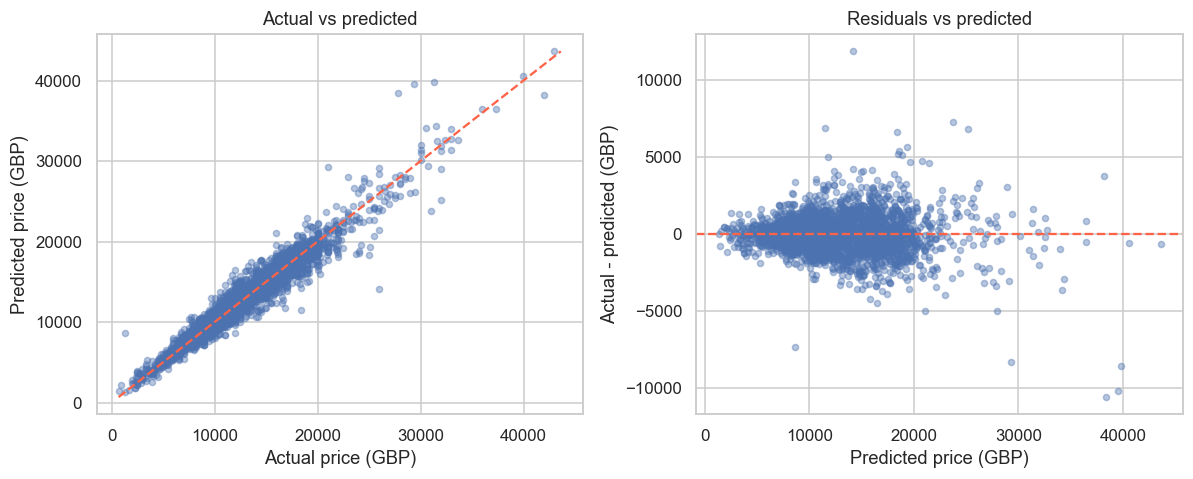

In [14]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y_test, y_pred, alpha=.4, s=16)
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())
axes[0].plot([lo, hi], [lo, hi], "--", color="tomato")
axes[0].set(xlabel="Actual price (GBP)", ylabel="Predicted price (GBP)", title="Actual vs predicted")
axes[1].scatter(y_pred, residuals, alpha=.4, s=16)
axes[1].axhline(0, linestyle="--", color="tomato")
axes[1].set(xlabel="Predicted price (GBP)", ylabel="Actual - predicted (GBP)", title="Residuals vs predicted")
fig.tight_layout()
plt.show()
print("Residual mean (GBP):", round(float(residuals.mean()), 2))
print("Residual median (GBP):", round(float(residuals.median()), 2))

## 08 | Conclusion and handoff

Complete this conclusion from the tables and residual plots produced by a fresh run. Include the selected model, all candidate CV results, the baseline and selected holdout MAE/RMSE/R², and a plain-language interpretation of typical error in GBP. Note whether residual spread or bias changes across the prediction range.

**Limitations:** these are asking/listing prices, not confirmed transaction prices; the source may be geographically or temporally limited; vehicle condition, trim, ownership history, and location are not represented; the random split can place similar listings in both train and test; and the anomalous 2060 record was excluded without reconstructing its true year. Consider group-aware/time-aware validation if listing identity or dates become available. Results are descriptive associations, not causal effects.

**Reproducibility:** source file `ford.csv`; cleaned export `ford_cleaned.csv`; random seed 42; holdout 20%; five-fold shuffled training CV; Python kernel `sample1`. No model artifact is saved.